# Building a Custom Model: NODDI with Restricted Soma and Per-Compartment T₂

This notebook is a step-by-step guide to **building a bespoke multi-compartment model from scratch** and fitting it using the existing infrastructure.

The model combines ideas from NODDI and SANDI:

| Compartment | Signal model | Key parameters |
|---|---|---|
| Neurites | Watson-dispersed sticks | `d_in`, `kappa`, `theta`, `phi`, `t2_neurite` |
| Extra-axonal | Watson-dispersed zeppelin (same FOD as neurites) | `d_in`, `d_perp`, `kappa`, `theta`, `phi`, `t2_extra` |
| Soma | Restricted sphere (GPD approximation) | `r_soma`, `d_soma`, `t2_soma` |
| CSF | Isotropic Gaussian ball | `d_csf`, `t2_csf` |

Each compartment carries a **different T₂ relaxation time**. At any given echo time (TE), the *apparent* contribution of each compartment to the signal differs from its volume fraction — sometimes dramatically, because CSF has a much longer T₂ than tissue.

By the end of this notebook you will understand:
- how the string-based parameter system links compartments to values,
- how to wrap any compartment in `T2Relaxation`,
- how to package a model as a reusable `ModelPreset` function,
- and how to simulate and fit with the existing `LeastSquaresFitter`.

In [11]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import (
    Acquisition,
    Ball,
    Component,
    LeastSquaresFitter,
    Model,
    ModelPreset,
    Parameter,
    ParameterSpace,
    Simplex,
    Sphere,
    Stick,
    T2Relaxation,
    Zeppelin,
)
from dmri_models.acquisitions import hcp
from dmri_models.compartments import FODConvolved, WatsonFOD

rng = np.random.default_rng(42)

## 1 — How the parameter system works

Every compartment takes **parameter name strings** in its constructor, not values.
When `.signal(acquisition, parameters)` is called, it looks up its values from the `parameters` dict by those strings at runtime.

This means:
- You choose the parameter names freely.
- The same string in the constructor and in the dict must match exactly.
- **Using the same name in two compartments links them to a single shared value** — for example, both the neurite stick and the extra-axonal zeppelin use `"d_in"` to enforce equal axial diffusivity without any extra coupling code.
- `T2Relaxation` follows the same convention: it takes the T₂ parameter name as a string and looks it up from the same dict.

A small demo:

In [12]:
_acq = Acquisition.from_b_values(
    [0, 1, 2], b_unit="ms/um^2", gradients=[[0,0,0],[1,0,0],[0,1,0]]
)

# Compartment uses the label 'd_in'; the dict supplies the value.
stick = Stick(diffusivity="d_in", orientation="axis")
print("signal:", stick.signal(_acq, {"d_in": 1.7, "axis": np.array([1.0, 0.0, 0.0])}))

# Rename the parameter — the maths is identical, the label is different.
stick2 = Stick(diffusivity="my_d", orientation="my_axis")
print("same: ", stick2.signal(_acq, {"my_d": 1.7, "my_axis": np.array([1.0, 0.0, 0.0])}))

signal: [1.         0.18268352 1.        ]
same:  [1.         0.18268352 1.        ]


## 2 — Acquisition

We use the HCP preset extended to **five echo times** (TE = 20, 40, 60, 80, 100 ms).  This gives 5 × 288 = 1440 measurements in total.

The `multi_te_acquisition` helper tiles every HCP measurement across the chosen echo times.  All diffusion fields (b-values, gradients, PGSE timing) are identical across TEs — only `echo_time` varies per measurement.  `T2Relaxation` uses the per-measurement `echo_time` field to apply the correct exp(−TE/T₂) weighting for each compartment.

With measurements spanning five TEs, the per-compartment T₂ values become estimable alongside the diffusion parameters.

In [13]:
acquisition = hcp()
acquisition.print_summary()
TE_single = float(acquisition.echo_time[0])
print(f"\nDefault HCP echo time: {TE_single} ms")


def multi_te_acquisition(base_acq: Acquisition, echo_times) -> Acquisition:
    """Replicate a base acquisition at multiple echo times.

    Each TE produces a complete copy of the base acquisition's measurements,
    giving n_te * n_measurements total measurements.  All acquisition fields
    (b-values, gradients, timing) are identical across TEs; only echo_time
    varies.  The resulting per-measurement echo_time field is what
    T2Relaxation uses to compute per-compartment T2 weighting.

    Parameters
    ----------
    base_acq:
        The acquisition to replicate.
    echo_times:
        Sequence of echo times in ms.  Each entry produces one full copy of
        the acquisition's measurements.
    """
    echo_times = np.asarray(echo_times, dtype=float)
    n_te = len(echo_times)

    def tile1d(v):
        return None if v is None else np.tile(v, n_te)

    def tile2d(v):
        return None if v is None else np.tile(v, (n_te, 1))

    return Acquisition(
        b_values=tile1d(base_acq.b_values),
        gradients=tile2d(base_acq.gradients),
        b_tensor_shape=tile1d(base_acq.b_tensor_shape),
        pulse_duration=tile1d(base_acq.pulse_duration),
        diffusion_time=tile1d(base_acq.diffusion_time),
        gradient_strength=tile1d(base_acq.gradient_strength),
        # Each TE block covers all n measurements, so repeat each TE value n times.
        echo_time=np.repeat(echo_times, base_acq.n_measurements),
        inversion_time=tile1d(base_acq.inversion_time),
        repetition_time=tile1d(base_acq.repetition_time),
    )


ECHO_TIMES = [20.0, 40.0, 60.0, 80.0, 100.0]  # ms
TE = ECHO_TIMES
acq_multi_te = multi_te_acquisition(acquisition, ECHO_TIMES)

print(f"\nMulti-TE acquisition:")
print(f"  {len(ECHO_TIMES)} echo times: {ECHO_TIMES} ms")
print(f"  {acquisition.n_measurements} measurements per TE")
print(f"  {acq_multi_te.n_measurements} measurements total")
acq_multi_te.print_summary()

----------------------------------------------------------------
Acquisition summary
- measurements: 288
- b-value shells (ms/um^2): 4 (tolerance: 0.100)
  - b=0.000: 18 measurements, 18 non-zero directions
  - b=0.998: 90 measurements, 90 non-zero directions
  - b=1.998: 90 measurements, 90 non-zero directions
  - b=2.996: 90 measurements, 90 non-zero directions
- gradient directions: 288 unique non-zero across 288 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 10.600
- diffusion time (ms): 43.100
- gradient strength (T/m): 0.000 to 0.097
- echo time (ms): 89.500
- inversion time: n/a
- repetition time (ms): 5520.000
----------------------------------------------------------------

Default HCP echo time: 89.5 ms

Multi-TE acquisition:
  5 echo times: [20.0, 40.0, 60.0, 80.0, 100.0] ms
  288 measurements per TE
  1440 measurements total
----------------------------------------------------------------
Acquisition summary
- measurements: 1440
- b-value she

## 3 — Packaging the model as a reusable preset function

The pattern used by `sandi()` and `noddi()` is:

1. Build a `Model` from `Component` objects (each wrapping a compartment).
2. Define a `ParameterSpace` with bounds, fixed parameters, and simplex constraints for fractions.
3. Return a `ModelPreset(model, parameters)` — a simple named pair that the fitters accept directly.

Wrapping everything in a function lets callers toggle options (fix or free T₂, diffusivities, etc.) without repeating the boilerplate.  The T₂ values can be passed in as arguments so they match literature values for the field strength being used.

A few design decisions to note:

- **Shared FOD.** A single `WatsonFOD` instance is passed to both the neurite and extra-axonal `FODConvolved` compartments.  Because they reference the same `kappa`, `theta`, `phi` strings, the same orientation distribution governs both — consistent with NODDI assumptions.
- **Fixed diffusivities by default.** `d_in`, `d_soma`, and `d_csf` are fixed to literature values at construction time.  This mirrors standard NODDI and SANDI practice.  Set `vary=True` to release them.
- **T₂ fixed by default.** Fitting per-compartment T₂ simultaneously requires multi-TE data.  At a single TE the T₂ values should be supplied as arguments (from the literature or from a separate measurement) and fixed during fitting.

In [14]:
def noddi_with_soma(
    *,
    vary_kappa: bool = True,
    vary_r_soma: bool = True,
    vary_d_perp: bool = True,
    vary_t2: bool = False,
    t2_neurite: float = 80.0,   # ms  intra-axonal at 3 T
    t2_extra: float = 60.0,     # ms  extra-axonal
    t2_soma: float = 45.0,      # ms  intra-somatic
    t2_csf: float = 1500.0,     # ms  free water
    fod_quadrature_theta: int = 16,
    fod_quadrature_phi: int = 32,
) -> ModelPreset:
    """NODDI-style model extended with a restricted soma compartment and per-compartment T2.

    The neurite and extra-axonal compartments share a Watson FOD (same kappa,
    theta, phi).  Every compartment is wrapped in T2Relaxation, so the
    acquisition must supply an echo_time field.

    Parameters
    ----------
    vary_kappa:
        Whether to fit the Watson concentration parameter.
    vary_r_soma:
        Whether to fit the soma radius.
    vary_d_perp:
        Whether to fit extra-axonal transverse diffusivity independently.
        To enforce NODDI tortuosity coupling instead, replace the Zeppelin with
        NODDIExtraNeurite, which computes d_perp from the fractions internally.
    vary_t2:
        Whether to fit the per-compartment T2 values.  Requires multi-TE data
        for reliable estimation; typically these are fixed at literature values.
    t2_neurite, t2_extra, t2_soma, t2_csf:
        Initial (and fixed, when vary_t2=False) T2 values in ms.
    fod_quadrature_theta, fod_quadrature_phi:
        Quadrature grid size for the Watson FOD spherical convolution.
        Increase for higher accuracy at the cost of compute time.
    """
    # A single WatsonFOD instance is shared between neurite and extra-axonal
    # compartments, enforcing the same orientation distribution for both.
    fod = WatsonFOD(
        kappa="kappa",
        theta="theta",
        phi="phi",
        n_theta=fod_quadrature_theta,
        n_phi=fod_quadrature_phi,
    )

    model = Model([
        Component(
            "neurite",
            T2Relaxation(
                compartment=FODConvolved(
                    response=Stick(diffusivity="d_in", orientation="axis"),
                    fod=fod,
                    orientation_parameter="axis",
                ),
                t2="t2_neurite",
            ),
        ),
        Component(
            "extra",
            T2Relaxation(
                compartment=FODConvolved(
                    response=Zeppelin(
                        parallel_diffusivity="d_in",
                        perpendicular_diffusivity="d_perp",
                        orientation="axis",
                    ),
                    fod=fod,
                    orientation_parameter="axis",
                ),
                t2="t2_extra",
            ),
        ),
        Component(
            "soma",
            T2Relaxation(
                compartment=Sphere(radius="r_soma", diffusivity="d_soma"),
                t2="t2_soma",
            ),
        ),
        Component(
            "csf",
            T2Relaxation(
                compartment=Ball(diffusivity="d_csf"),
                t2="t2_csf",
            ),
        ),
    ])

    parameter_space = ParameterSpace(
        [
            Parameter("S0",         1.0,        (0.05,  2.0)),
            Parameter("d_in",       2.2,        (0.5,   3.0),    vary=False),
            Parameter("d_perp",     0.5,        (0.0,   2.5),    vary=vary_d_perp),
            Parameter("d_soma",     3.0,        (1.0,   3.5),    vary=False),
            Parameter("r_soma",     8.0,        (1.0,  15.0),    vary=vary_r_soma),
            Parameter("d_csf",      3.0,        (1.5,   3.5),    vary=False),
            Parameter("kappa",      2.0,        (0.0,  64.0),    vary=vary_kappa),
            Parameter("theta",      np.pi / 2,  (0.0,  np.pi)),
            Parameter("phi",        0.0,        (-np.pi, np.pi)),
            Parameter("t2_neurite", t2_neurite, (20.0,  200.0),  vary=vary_t2),
            Parameter("t2_extra",   t2_extra,   (20.0,  200.0),  vary=vary_t2),
            Parameter("t2_soma",    t2_soma,    (10.0,  200.0),  vary=vary_t2),
            Parameter("t2_csf",     t2_csf,     (500.0, 3000.0), vary=vary_t2),
        ],
        simplexes=[
            Simplex(
                ("neurite_fraction", "extra_fraction", "soma_fraction", "csf_fraction"),
                (0.50, 0.25, 0.10, 0.15),
            )
        ],
    )

    return ModelPreset(model=model, parameters=parameter_space)

In [15]:
preset = noddi_with_soma()

print("Free parameters (optimised or sampled):")
for name in preset.parameters.varying_names:
    print(f"  {name}")

print("\nFixed parameters (held at initial values):")
for p in preset.parameters.parameters:
    if not p.vary:
        print(f"  {p.name} = {p.initial}")

Free parameters (optimised or sampled):
  S0
  d_perp
  r_soma
  kappa
  theta
  phi
  neurite_fraction/csf_fraction
  extra_fraction/csf_fraction
  soma_fraction/csf_fraction

Fixed parameters (held at initial values):
  d_in = 2.2
  d_soma = 3.0
  d_csf = 3.0
  t2_neurite = 80.0
  t2_extra = 60.0
  t2_soma = 45.0
  t2_csf = 1500.0


## 4 — T₂ effects on apparent signal fractions

At any given TE, each compartment’s contribution to the b = 0 signal is weighted by exp(−TE / T₂).
Because CSF has a much longer T₂ than tissue, it can contribute a large fraction of the measured b = 0 signal even when its **volume fraction** is small.

The table below makes this concrete for the HCP echo time.  Ignoring T₂ would lead to strongly biased fraction estimates.

In [17]:
# Ground-truth parameters for the synthetic experiment.
true_parameters = {
    "S0": 1.0,
    # Diffusivities (um^2/ms)
    "d_in":   2.2,
    "d_perp": 0.55,
    "d_soma": 3.0,
    "r_soma": 7.0,   # um
    "d_csf":  3.0,
    # Watson FOD
    "kappa":  2.5,
    "theta":  0.9,   # rad
    "phi":    1.3,   # rad
    # T2 values (ms)  —  typical WM at 3T (based on the multi-TE SANDI and multi-TE NODDI papers)
    "t2_neurite": 80.0,
    "t2_extra":   60.0,
    "t2_soma":    45.0,
    "t2_csf":  1500.0,
    # Volume fractions
    "neurite_fraction": 0.50,
    "extra_fraction":   0.25,
    "soma_fraction":    0.10,
    "csf_fraction":     0.15,
}

for te in ECHO_TIMES:
    print(f"\nEcho time: {te} ms")
    print()
    print(f"{'Compartment':>12}  {'Volume f':>9}  {'T2 (ms)':>9}  {'exp(-TE/T2)':>12}  {'f x weight':>11}")
    print("-" * 62)

    apparent = {}
    for c, t2k, fk in zip(compartments, t2_keys, frac_keys):
        f = true_parameters[fk]
        t2 = true_parameters[t2k]
        w = np.exp(-te / t2)
        apparent[c] = f * w
        print(f"{c:>12}  {f:>9.2f}  {t2:>9.1f}  {w:>12.4f}  {f*w:>11.4f}")

    total = sum(apparent.values())
    print("-" * 62)
    print(f"\nTotal T2-weighted b=0 signal / S0 = {total:.4f}")
    print("\nApparent share of the b=0 signal vs volume fraction:")
    for c in compartments:
        vol = true_parameters[c + "_fraction"]
        app = apparent[c] / total
        print(f"  {c:>12}: {100*app:.1f}% of b=0 signal   (volume fraction {100*vol:.0f}%)")


Echo time: 20.0 ms

 Compartment   Volume f    T2 (ms)   exp(-TE/T2)   f x weight
--------------------------------------------------------------
     neurite       0.50       80.0        0.7788       0.3894
       extra       0.25       60.0        0.7165       0.1791
        soma       0.10       45.0        0.6412       0.0641
         csf       0.15     1500.0        0.9868       0.1480
--------------------------------------------------------------

Total T2-weighted b=0 signal / S0 = 0.7807

Apparent share of the b=0 signal vs volume fraction:
       neurite: 49.9% of b=0 signal   (volume fraction 50%)
         extra: 22.9% of b=0 signal   (volume fraction 25%)
          soma: 8.2% of b=0 signal   (volume fraction 10%)
           csf: 19.0% of b=0 signal   (volume fraction 15%)

Echo time: 40.0 ms

 Compartment   Volume f    T2 (ms)   exp(-TE/T2)   f x weight
--------------------------------------------------------------
     neurite       0.50       80.0        0.6065       0.303

## 5 — Simulate synthetic multi-TE data

In [19]:
model = preset.model

SNR   = 20
sigma = true_parameters["S0"] / SNR

signal_true  = model.signal(acq_multi_te, true_parameters)
signal_noisy = signal_true + rng.normal(0.0, sigma, size=signal_true.shape)

print(f"Total measurements: {acq_multi_te.n_measurements}  ({len(ECHO_TIMES)} TEs × {acquisition.n_measurements})")
print(f"Signal range:       [{signal_true.min():.4f}, {signal_true.max():.4f}]")
print(f"Noise sigma:        {sigma:.4f}")

# Show mean b=0 signal at each TE to make T2 decay visible.
print("\nMean b=0 signal at each TE:")
for te in ECHO_TIMES:
    te_mask = np.isclose(acq_multi_te.echo_time, te)
    b0_mask = acq_multi_te.b_values < 0.05
    mean_b0 = float(signal_true[te_mask & b0_mask].mean())
    print(f"  TE = {te:5.0f} ms:  {mean_b0:.4f}")

Total measurements: 1440  (5 TEs × 288)
Signal range:       [0.0297, 0.7807]
Noise sigma:        0.0500

Mean b=0 signal at each TE:
  TE =    20 ms:  0.7807
  TE =    40 ms:  0.6188
  TE =    60 ms:  0.4986
  TE =    80 ms:  0.4089
  TE =   100 ms:  0.3416


## 6 — Fit with LeastSquaresFitter

With five echo times available the per-compartment T₂ values are no longer confounded with the fractions and can be estimated jointly.  We set `vary_t2=True` and let the fitter optimise T₂ alongside the diffusion and orientation parameters.

The fitter's built-in DTI initialisation seeds `theta` and `phi` from the low-b data automatically.

In [ ]:
# With multiple TEs we can free the T2 parameters.
# Supply sensible starting values and bounds; the optimiser will refine them.
fit_preset = noddi_with_soma(
    vary_t2=True,
    t2_neurite=70.0,   # start slightly away from true values
    t2_extra=55.0,
    t2_soma=40.0,
    t2_csf=1200.0,
)

fitter = LeastSquaresFitter(fit_preset.model, fit_preset.parameters)
fit = fitter.fit(
    acq_multi_te,
    signal_noisy,
    n_starts=10,
    max_nfev=3000,
    rng=rng,
)

print(f"Success: {fit.success} | Cost: {fit.cost:.4f} | Evaluations: {fit.n_evaluations}")

Success: True | Cost: 732.0713 | Evaluations: 41


In [ ]:
ordered_diffusion = [
    "S0", "d_in", "d_perp", "d_soma", "r_soma", "d_csf",
    "kappa", "theta", "phi",
    "neurite_fraction", "extra_fraction", "soma_fraction", "csf_fraction",
]
ordered_t2 = ["t2_neurite", "t2_extra", "t2_soma", "t2_csf"]

print(f"{'Parameter':>20}  {'True':>10}  {'Fitted':>10}  {'Error':>10}")
print("-" * 56)
for name in ordered_diffusion + ordered_t2:
    tv = true_parameters[name]
    fv = fit.parameters[name]
    print(f"{name:>20}  {tv:>10.4f}  {fv:>10.4f}  {fv - tv:>+10.4f}")

           Parameter        True      Fitted       Error
--------------------------------------------------------
                  S0      1.0000      0.9985     -0.0015
                d_in      2.2000      2.2000     +0.0000
              d_perp      0.5500      0.3175     -0.2325
              d_soma      3.0000      3.0000     +0.0000
              r_soma      7.0000      2.4337     -4.5663
               d_csf      3.0000      3.0000     +0.0000
               kappa      2.5000      2.3479     -0.1521
               theta      0.9000      2.2359     +1.3359
                 phi      1.3000     -1.8382     -3.1382
    neurite_fraction      0.5000      0.4604     -0.0396
      extra_fraction      0.2500      0.3259     +0.0759
       soma_fraction      0.1000      0.0570     -0.0430
        csf_fraction      0.1500      0.1567     +0.0067
          t2_neurite     80.0000     83.5584     +3.5584
            t2_extra     60.0000     56.9759     -3.0241
             t2_soma     45.000

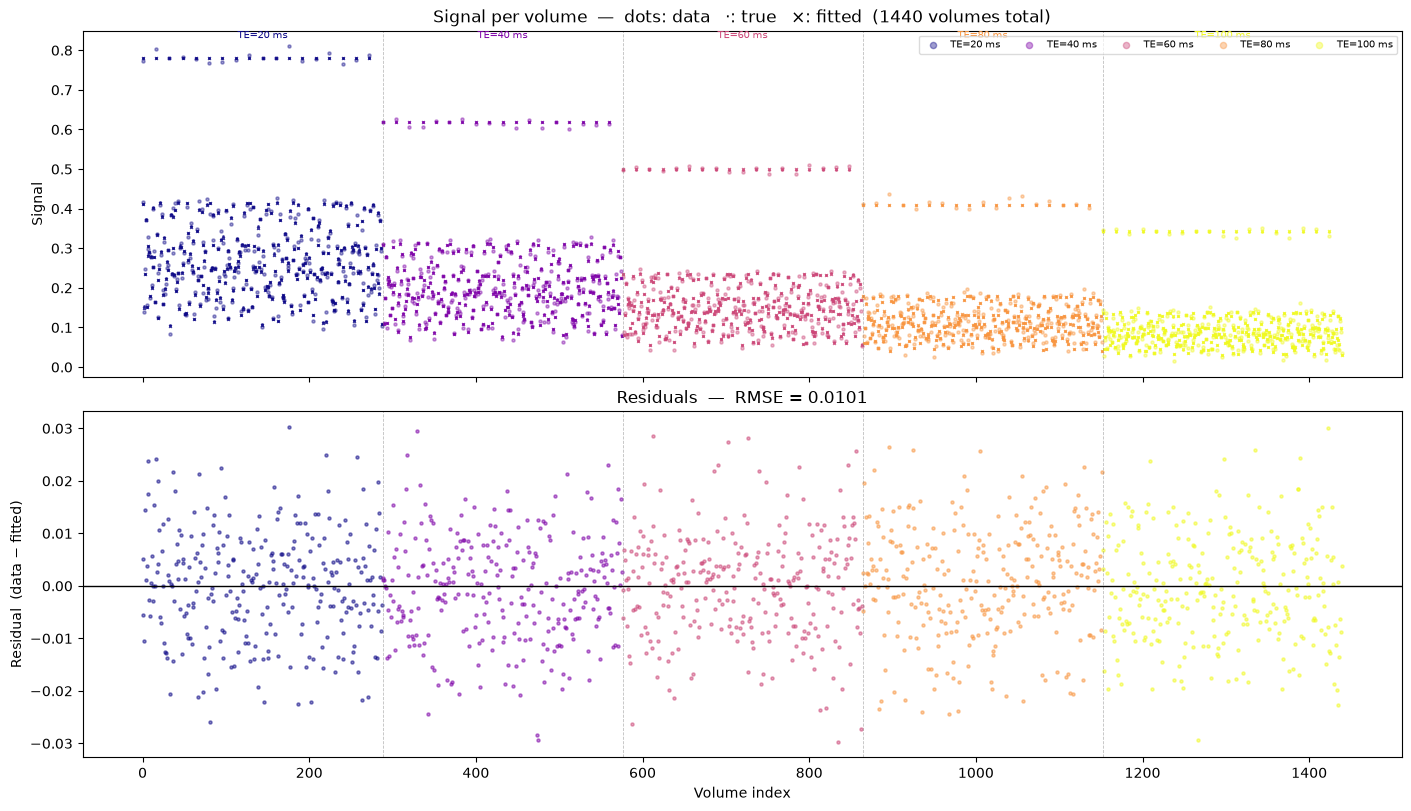

In [ ]:
vol_idx   = np.arange(acq_multi_te.n_measurements)
tes        = acq_multi_te.echo_time
te_levels  = sorted(set(float(t) for t in ECHO_TIMES))
n_per_te   = acquisition.n_measurements   # number of volumes per TE block

cmap   = plt.get_cmap("plasma")
colors = {te: cmap(i / (len(te_levels) - 1)) for i, te in enumerate(te_levels)}

residuals = signal_noisy - fit.predicted_signal

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True, sharex=True)

# ── Top panel: data, true signal, and predicted signal vs volume index ─────────
for i, te in enumerate(te_levels):
    mask = np.isclose(tes, te)
    idx  = vol_idx[mask]
    c    = colors[te]
    axes[0].scatter(idx, signal_noisy[mask],        s=5,   alpha=0.4, color=c,
                    label=f"TE={te:.0f} ms")
    axes[0].plot(   idx, signal_true[mask],          ".",   ms=2, alpha=0.7, color=c)
    axes[0].plot(   idx, fit.predicted_signal[mask], "x",   ms=2, alpha=0.8, color=c)

# Vertical separators between TE blocks.
for i in range(1, len(te_levels)):
    axes[0].axvline(i * n_per_te, color="grey", linewidth=0.6, linestyle="--", alpha=0.5)

# Annotate each TE block.
for i, te in enumerate(te_levels):
    axes[0].text(
        (i + 0.5) * n_per_te, axes[0].get_ylim()[1] if axes[0].get_ylim()[1] != 0.0 else 1.0,
        f"TE={te:.0f} ms", ha="center", va="top", fontsize=7, color=colors[te],
    )

axes[0].set_ylabel("Signal")
axes[0].set_title(
    f"Signal per volume  —  dots: data   ·: true   ×: fitted  ({acq_multi_te.n_measurements} volumes total)"
)
axes[0].legend(
    ncol=len(te_levels), fontsize=7, markerscale=2,
    loc="upper right", framealpha=0.7,
)

# ── Bottom panel: residuals (data − fitted) vs volume index ──────────────────
for te in te_levels:
    mask = np.isclose(tes, te)
    axes[1].scatter(vol_idx[mask], residuals[mask], s=5, alpha=0.5, color=colors[te])

for i in range(1, len(te_levels)):
    axes[1].axvline(i * n_per_te, color="grey", linewidth=0.6, linestyle="--", alpha=0.5)

axes[1].axhline(0.0, color="k", linewidth=1)
axes[1].set_xlabel("Volume index")
axes[1].set_ylabel("Residual  (data − fitted)")
axes[1].set_title(f"Residuals  —  RMSE = {float(np.sqrt(np.mean(residuals**2))):.4f}")

plt.show()

## Key takeaways

1. **Parameter names are the glue.** The string `"d_in"` in both `Stick` and `Zeppelin` links them to a single shared value — no coupling code needed.

2. **`T2Relaxation` wraps any compartment.** It reads `echo_time` from the acquisition per-measurement and multiplies by exp(−TE / T₂).  To add T₂ to any model, wrap each compartment and add a `Parameter` entry for its T₂.

3. **Multi-TE data unlocks T₂ estimation.** With a single TE, T₂ values are unidentifiable from fractions.  Repeating measurements at multiple TEs breaks that confound — `multi_te_acquisition` tiles any base acquisition across the chosen echo times.

4. **T₂ biases apparent fractions.** At TE = 89.5 ms (single HCP acquisition), CSF (15% volume) contributes ~40% of the b = 0 signal due to its long T₂.  The right panel shows how this T₂ decay is captured across the five TEs.

5. **Creating a new model just means writing a function** that returns `ModelPreset(Model([...]), ParameterSpace([...]))`.  Everything else — fitting, MCMC, DTI initialisation, batch processing — works unchanged.